# Comparing the predictive performance of machine learning algorithms for household expenditure

This notebook consists of two sections:
1. The first section I employ the dataset prepeared and saved at the end of the EDA notebook. 
2. The second section employes all features available in the dataset by loading the raw dataset and estimating Random Forest and XGBoost considering all features unlike the first section to compare the predictive performances.

Results section at the end of the notebook summarizes all results and concludes with concluding remarks.

## Linear regression
- I load the data saved at the end of the EDA script to run linear regression model to predict consumption. 

In [1]:
# loading packages
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

In [2]:
lr_df = pd.read_pickle("../data/df.pkl")
lr_df.head()

,weight,utl_exp_ppp17,hsize,age,sworkershh,share_secondary,sfworkershh,cons_ppp17,male_Male,owner_Owner,...,educ_max_Complete Tertiary Education,educ_max_Incomplete Primary Education,educ_max_Incomplete Secondary Education,educ_max_Incomplete Tertiary Education,educ_max_Never attended,any_nonagric_Yes,urban_Urban,dep_ratio,no_adult,adult_female_ratio
0,75,594.80627,1,75,0.000000,0.000000,0.0,25.258402,0,1,...,0,0,1,0,0,0,1,0.000000,1,0.000000
1,150,1676.27230,2,61,0.000000,0.000000,0.0,16.996706,0,1,...,1,0,0,0,0,0,1,0.000000,0,0.500000
2,375,506.93719,5,49,0.666667,0.333333,0.5,13.671848,1,1,...,0,0,0,1,0,1,1,0.000000,0,0.200000
3,375,824.61786,5,58,1.250000,0.250000,0.2,7.189475,1,0,...,0,0,0,1,0,1,1,0.000000,0,0.200000
4,525,351.47644,7,57,0.666667,0.333333,0.5,12.308855,1,1,...,1,0,0,0,0,1,1,0.142857,0,0.285714


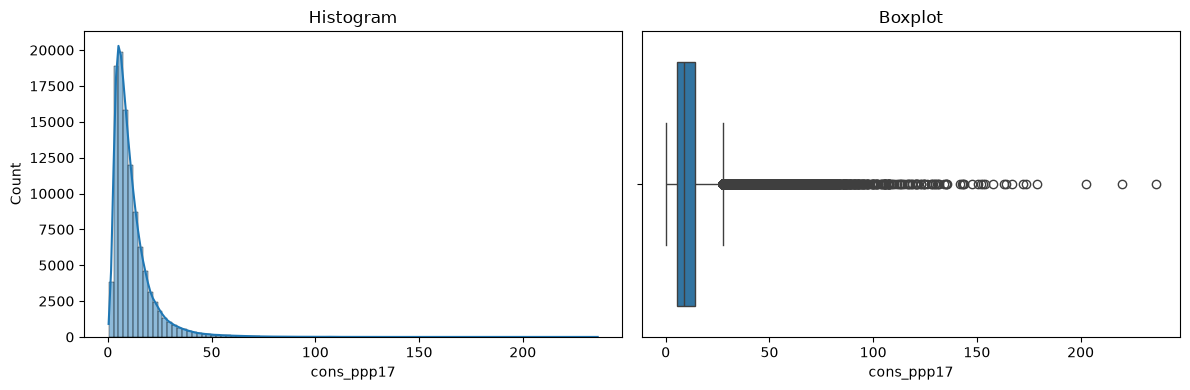

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=lr_df, x="cons_ppp17", bins=100, kde=True, ax=axes[0])
sns.boxplot(data=lr_df, x="cons_ppp17", ax=axes[1])

axes[0].set_title("Histogram")
axes[1].set_title("Boxplot")
plt.tight_layout()
plt.show()

In [4]:
x = lr_df.drop(columns= ["cons_ppp17", "weight", "share_secondary"]).copy()
y = np.log(lr_df.cons_ppp17).copy()
sam_weight = lr_df.weight
x_train, x_test, y_train, y_test, w_train, w_test = train_test_split(x, y, sam_weight, test_size= 0.2, stratify= lr_df["urban_Urban"] , random_state= 1234 )

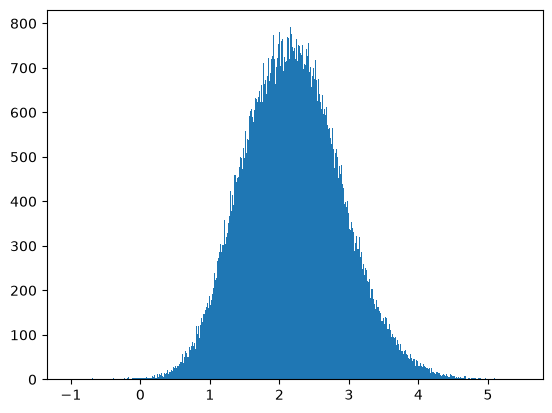

In [5]:
plt.hist(y, bins= 500);

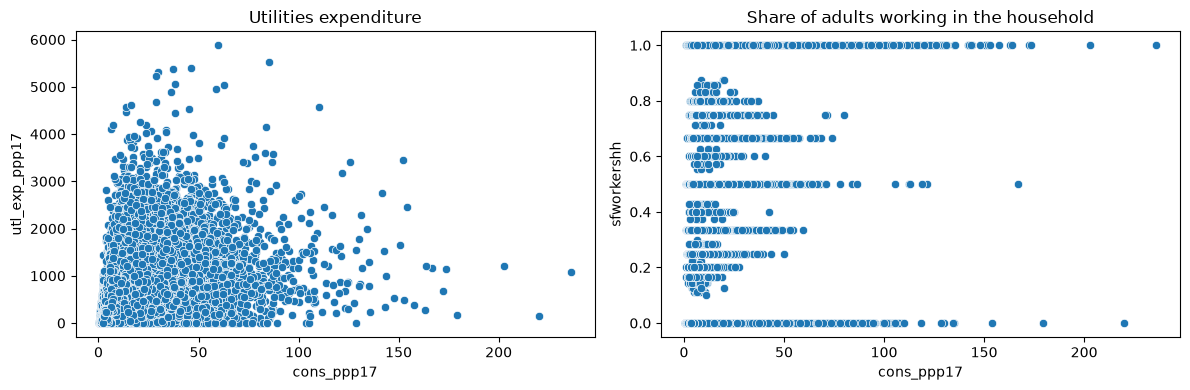

In [6]:
# Let's look closely at the two variables that had comperatively stronger association with the outcome variable. 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(data= lr_df, x= "cons_ppp17", y= "utl_exp_ppp17", ax= axes[0]);
sns.scatterplot(data= lr_df, x= "cons_ppp17", y= "sfworkershh", ax= axes[1]);

axes[0].set_title("Utilities expenditure")
axes[1].set_title("Share of adults working in the household")
plt.tight_layout()
plt.show()


In [7]:
x_train.describe()

,utl_exp_ppp17,hsize,age,sworkershh,sfworkershh,male_Male,owner_Owner,water_No access,toilet_No access,elect_No access,...,educ_max_Complete Tertiary Education,educ_max_Incomplete Primary Education,educ_max_Incomplete Secondary Education,educ_max_Incomplete Tertiary Education,educ_max_Never attended,any_nonagric_Yes,urban_Urban,dep_ratio,no_adult,adult_female_ratio
count,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,...,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000,83300.000000
mean,511.870471,3.619184,52.617839,0.855650,0.320736,0.727095,0.734790,0.181873,0.296351,0.088752,...,0.283217,0.108175,0.099376,0.122725,0.040504,0.664046,0.612701,0.129421,0.078872,0.319449
std,438.673168,1.933540,15.706655,0.380667,0.400912,0.445455,0.441448,0.385742,0.456650,0.284386,...,0.450564,0.310604,0.299168,0.328123,0.197140,0.472326,0.487136,0.176591,0.269540,0.235544
min,0.000000,1.000000,15.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,193.532300,2.000000,41.000000,0.600000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000
50%,412.036500,3.000000,52.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.300000
75%,723.230410,5.000000,64.000000,1.000000,0.500000,1.000000,1.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.250000,0.000000,0.500000
max,5880.471200,21.000000,98.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.857143,1.000000,1.500000


In [8]:
x_test.describe()

,utl_exp_ppp17,hsize,age,sworkershh,sfworkershh,male_Male,owner_Owner,water_No access,toilet_No access,elect_No access,...,educ_max_Complete Tertiary Education,educ_max_Incomplete Primary Education,educ_max_Incomplete Secondary Education,educ_max_Incomplete Tertiary Education,educ_max_Never attended,any_nonagric_Yes,urban_Urban,dep_ratio,no_adult,adult_female_ratio
count,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,...,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000,20826.000000
mean,505.106144,3.585566,52.506866,0.858652,0.320644,0.720686,0.732450,0.177470,0.296937,0.086478,...,0.279266,0.108806,0.102324,0.122299,0.040574,0.667675,0.612696,0.128297,0.078075,0.319862
std,432.666859,1.902699,15.793097,0.381043,0.400899,0.448673,0.442692,0.382076,0.456919,0.281076,...,0.448649,0.311404,0.303081,0.327639,0.197307,0.471058,0.487146,0.176238,0.268297,0.236950
min,0.000000,1.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189.256550,2.000000,40.000000,0.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000
50%,405.580380,3.000000,51.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.333333
75%,716.471250,5.000000,64.000000,1.000000,0.500000,1.000000,1.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.250000,0.000000,0.500000
max,4894.494100,21.000000,98.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.800000,1.000000,1.000000


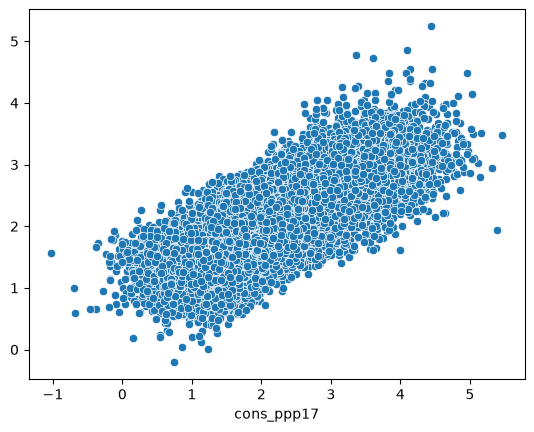

In [9]:
lm = LinearRegression()
lm.fit(x_train, y_train, sample_weight= w_train)
y_pred = lm.predict(x_train)
sns.scatterplot(x = y_train, y= y_pred); # errors seem normal

In [10]:
print(f"Training R2: {metrics.r2_score(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Training MAE: {metrics.mean_absolute_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Training RMSE: {metrics.root_mean_squared_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")



Training R2: 0.63
Training MAE: 0.31
Training RMSE: 0.40


In [11]:
y_pred_test= lm.predict(x_test)
print(f"Test R2 (log values): {metrics.r2_score(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")
print(f"Test MAE (log values): {metrics.mean_absolute_error(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")
print(f"Test RMSE (log values): {metrics.root_mean_squared_error(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")

cons_actual = np.exp(y_test)
cons_pred = np.exp(y_pred_test)
print(f"Test R2 (actual values): {metrics.r2_score(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")
print(f"Test MAE (actual values): {metrics.mean_absolute_error(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")
print(f"Test RMSE (actual values): {metrics.root_mean_squared_error(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")

Test R2 (log values): 0.64
Test MAE (log values): 0.31
Test RMSE (log values): 0.40
Test R2 (actual values): 0.51
Test MAE (actual values): 3.45
Test RMSE (actual values): 6.13


## Regularized Resression - Ridge

In [3]:
from sklearn.linear_model import Ridge
from sklearn import config_context
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [13]:
x = lr_df.drop(columns= ["cons_ppp17", "weight"]) # share_Secondary is not dropped
y = np.log(lr_df.cons_ppp17)
sam_weight = lr_df.weight
x_train, x_test, y_train, y_test, w_train, w_test = train_test_split(x, y, sam_weight, test_size= 0.2, stratify= lr_df["urban_Urban"] , random_state= 1234 )

In [14]:
cv = StratifiedKFold(n_splits= 5, shuffle= True, random_state= 1234)
folds = list(cv.split(x_train, x_train["urban_Urban"]))
# because we have samplign weights, it is more appropriate to use metadata routing so that each fold gets subset of weights when fitting
with config_context(enable_metadata_routing=True):
    pipeline = make_pipeline(
        StandardScaler().set_fit_request(sample_weight=True), # with pipe I ensure that scaling is done withing each fold 
        Ridge().set_fit_request(sample_weight=True),
    )

    weighted_mae = make_scorer(
        mean_absolute_error, greater_is_better=False
    ).set_score_request(sample_weight=True)

    ridge_search = GridSearchCV(
        estimator=pipeline,
        param_grid={"ridge__alpha": np.logspace(-3, 4, 30)},
        scoring=weighted_mae,
        cv=folds,
        refit=True,
    )

    ridge_search.fit(x_train, y_train, sample_weight=w_train)
y_pred = ridge_search.predict(x_train)

In [15]:
print(f"Ridge Training R2: {metrics.r2_score(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Ridge Training MAE: {metrics.mean_absolute_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Ridge Training RMSE: {metrics.root_mean_squared_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")

Ridge Training R2: 0.63
Ridge Training MAE: 0.31
Ridge Training RMSE: 0.40


In [16]:
y_pred_test= ridge_search.predict(x_test)
print(f"Ridge Test R2 (log values): {metrics.r2_score(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")
print(f"Ridge Test MAE (log values): {metrics.mean_absolute_error(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")
print(f"Ridge Test RMSE (log values): {metrics.root_mean_squared_error(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")

cons_actual = np.exp(y_test)
cons_pred = np.exp(y_pred_test)
print(f"Ridge Test R2 (actual values): {metrics.r2_score(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")
print(f"Ridge Test MAE (actual values): {metrics.mean_absolute_error(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")
print(f"Ridge Test RMSE (actual values): {metrics.root_mean_squared_error(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")

Ridge Test R2 (log values): 0.64
Ridge Test MAE (log values): 0.31
Ridge Test RMSE (log values): 0.40
Ridge Test R2 (actual values): 0.51
Ridge Test MAE (actual values): 3.45
Ridge Test RMSE (actual values): 6.13


## LASSO


In [2]:
from sklearn.linear_model import Lasso

In [18]:
cv = StratifiedKFold(n_splits= 5, shuffle= True, random_state= 1234)
folds = list(cv.split(x_train, x_train["urban_Urban"]))

with config_context(enable_metadata_routing=True):
    pipeline = make_pipeline(
        StandardScaler().set_fit_request(sample_weight=True),
        Lasso(max_iter=20_000).set_fit_request(sample_weight=True),
    )

    weighted_mae = metrics.make_scorer(
        metrics.mean_absolute_error, greater_is_better=False
    ).set_score_request(sample_weight=True)

    lasso_search = GridSearchCV(
        estimator=pipeline,
        param_grid={"lasso__alpha": np.logspace(-5, 0, 40)},
        scoring=weighted_mae,
        cv=folds,
        refit=True,
        error_score="raise",
    )
    lasso_search.fit(x_train, y_train, sample_weight=w_train)
    
y_pred = lasso_search.predict(x_train)

In [19]:
print(f"Lasso Training R2: {metrics.r2_score(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Lasso Training MAE: {metrics.mean_absolute_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Lasso Training RMSE: {metrics.root_mean_squared_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")

Lasso Training R2: 0.63
Lasso Training MAE: 0.31
Lasso Training RMSE: 0.40


In [20]:
y_pred_test= lasso_search.predict(x_test)
print(f"Lasso Test R2 (log values): {metrics.r2_score(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")
print(f"Lasso Test MAE (log values): {metrics.mean_absolute_error(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")
print(f"Lasso Test RMSE (log values): {metrics.root_mean_squared_error(y_true= y_test, y_pred= y_pred_test, sample_weight=w_test):.2f}")

cons_actual = np.exp(y_test)
cons_pred = np.exp(y_pred_test)
print(f"Lasso Test R2 (actual values): {metrics.r2_score(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")
print(f"Lasso Test MAE (actual values): {metrics.mean_absolute_error(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")
print(f"Lasso Test RMSE (actual values): {metrics.root_mean_squared_error(y_true= cons_actual, y_pred= cons_pred, sample_weight=w_test):.2f}")

Lasso Test R2 (log values): 0.64
Lasso Test MAE (log values): 0.31
Lasso Test RMSE (log values): 0.40
Lasso Test R2 (actual values): 0.51
Lasso Test MAE (actual values): 3.45
Lasso Test RMSE (actual values): 6.13


## Random Forests

In [21]:
from sklearn.ensemble import RandomForestRegressor

In [24]:
cv = StratifiedKFold(n_splits= 5, shuffle= True, random_state= 1234)
folds = list(cv.split(x_train, x_train["urban_Urban"]))

# 1st try, took 242 minutes. 
# param_grid = {
#     "n_estimators": [100, 200, 500],
#     "max_depth": [5, 10, 30, None],
#     "min_samples_leaf": [1, 5, 10],
#     "max_features": ["sqrt", 0.5, 1.0],
# }

# {'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 500}
param_grid = {
    "n_estimators": [500],
    "max_depth": [20, 30, 40, None],
    "min_samples_leaf": [3, 5, 8],
    "max_features": ["sqrt", "log2", 0.35],
}

with config_context(enable_metadata_routing=True):
    rf = RandomForestRegressor(
        random_state=1234,
        n_jobs=1,
    ).set_fit_request(sample_weight=True)

    weighted_mae = metrics.make_scorer(
        metrics.mean_absolute_error, greater_is_better=False
    ).set_score_request(sample_weight=True)

    rf_search = GridSearchCV(
        estimator=rf,
        param_grid= param_grid,
        scoring=weighted_mae,
        cv=folds,
        n_jobs = -1,
        refit=True,
        error_score="raise",
    )
    rf_search.fit(x_train, y_train, sample_weight=w_train)
    
print(rf_search.best_params_)

{'max_depth': 20, 'max_features': 0.35, 'min_samples_leaf': 8, 'n_estimators': 500}


In [25]:
y_pred = rf_search.predict(x_train)
print(f"Random Forest Training R2: {metrics.r2_score(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Random Forest Training MAE: {metrics.mean_absolute_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Random Forest Training RMSE: {metrics.root_mean_squared_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")

Random Forest Training R2: 0.78
Random Forest Training MAE: 0.24
Random Forest Training RMSE: 0.32


In [26]:
def print_model_metrics(model_name, y_true, y_pred, sample_weight):
    scores = {
        "R2": metrics.r2_score(y_true, y_pred, sample_weight=sample_weight),
        "MAE": metrics.mean_absolute_error(y_true, y_pred, sample_weight=sample_weight),
        "RMSE": metrics.root_mean_squared_error(
            y_true, y_pred, sample_weight=sample_weight
        ),
    }

    for metric_name, value in scores.items():
        print(f"{model_name} Test {metric_name}: {value:.2f}")
        
y_pred_test= rf_search.predict(x_test)
print_model_metrics("Random Forest", y_test, y_pred_test, w_test )

cons_actual = np.exp(y_test)
cons_pred = np.exp(y_pred_test)
print_model_metrics("Random Forest (actual values)", cons_actual, cons_pred, w_test )

Random Forest Test R2: 0.68
Random Forest Test MAE: 0.29
Random Forest Test RMSE: 0.37
Random Forest (actual values) Test R2: 0.58
Random Forest (actual values) Test MAE: 3.23
Random Forest (actual values) Test RMSE: 5.64


## XGBoost

In [27]:
from xgboost import XGBRegressor

In [28]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.1],
    "max_depth": [5, 10, None],
    "subsample": [0.5, 0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "gamma": [0, 0.1],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)
folds = list(cv.split(x_train, x_train["urban_Urban"]))

with config_context(enable_metadata_routing=True):
    xgb = XGBRegressor(
        objective="reg:squarederror",
        random_state=1234,
        n_jobs=1,
    ).set_fit_request(sample_weight=True)

    weighted_mse = metrics.make_scorer(
        metrics.mean_squared_error,
        greater_is_better=False,
    ).set_score_request(sample_weight=True)

    xgb_search = GridSearchCV(
        estimator=xgb,
        param_grid=param_grid,
        cv=folds,
        scoring=weighted_mse,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score="raise",
    )

    xgb_search.fit(x_train, y_train, sample_weight=w_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


In [29]:
print(xgb_search.best_params_)

{'colsample_bytree': 0.8, 'gamma': 0.1, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1.0}


In [30]:
y_pred = xgb_search.predict(x_train)
print(f"XGB Training R2: {metrics.r2_score(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"XGB Training MAE: {metrics.mean_absolute_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"XGB Training RMSE: {metrics.root_mean_squared_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")

XGB Training R2: 0.71
XGB Training MAE: 0.28
XGB Training RMSE: 0.36


In [31]:
y_pred_test= xgb_search.predict(x_test)
print_model_metrics("XGB", y_test, y_pred_test, w_test )

cons_actual = np.exp(y_test)
cons_pred = np.exp(y_pred_test)
print_model_metrics("XGB (actual values)", cons_actual, cons_pred, w_test )

XGB Test R2: 0.68
XGB Test MAE: 0.29
XGB Test RMSE: 0.37
XGB (actual values) Test R2: 0.60
XGB (actual values) Test MAE: 3.21
XGB (actual values) Test RMSE: 5.53


# Random Forest and XGBoost with all available features

In the above part of the notebook, I have estimated models with features that are commonly used in development economics literature. In this section, I employ all available features and compare the results at the end. 
Here I load the raw dataset and estimating Random Forest and XGBoost considering all features unlike the first section to compare the predictive performances.

## Random Forest

In [4]:
from sklearn.ensemble import RandomForestRegressor
consumption = pd.read_csv("../data/train_hh_gt.csv")
df = pd.read_csv("../data/train_hh_features.csv")
df = df.merge(consumption, how= "left", on=["hhid", "survey_id"], validate="1:1")
df.head()

,hhid,com,weight,strata,utl_exp_ppp17,male,hsize,num_children5,num_children10,num_children18,...,consumed4300,consumed4400,consumed4500,consumed4600,consumed4700,consumed4800,consumed4900,consumed5000,survey_id,cons_ppp17
0,100001,1,75,4,594.80627,Female,1,0,0,0,...,No,No,No,Yes,Yes,Yes,Yes,No,100000,25.258402
1,100002,1,150,4,1676.27230,Female,2,0,0,0,...,No,No,No,No,Yes,Yes,No,No,100000,16.996706
2,100003,1,375,4,506.93719,Male,5,0,0,2,...,Yes,No,Yes,Yes,Yes,Yes,No,Yes,100000,13.671848
3,100004,1,375,4,824.61786,Male,5,0,0,1,...,Yes,No,No,No,Yes,Yes,No,No,100000,7.189475
4,100005,1,525,4,351.47644,Male,7,1,0,0,...,No,No,Yes,No,Yes,Yes,Yes,No,100000,12.308855


In [5]:
df["dep_ratio"] = (df.num_children5 + df.num_children10) / df.hsize # not the exact definition of dependency raiton, but a still a good indicaotr of dependdency ration in this case
df["no_adult"] = np.where((df.num_adult_female == 0) & (df.num_adult_male == 0), 1, 0)
df["adult_female_ratio"] = df.num_adult_female / df.hsize
df = df.drop(["survey_id", "strata", "com", "hhid", "num_children5", "num_children10", "num_children18", "num_elderly", "num_adult_male", "num_adult_female", "sector1d", "region1", "region2", "region3", "region4", "region5", "region6", "region7"], axis =1)

In [6]:
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].apply(lambda var: var.astype("category").cat.codes)

df.head()

,weight,utl_exp_ppp17,male,hsize,age,owner,water,toilet,sewer,elect,...,consumed4500,consumed4600,consumed4700,consumed4800,consumed4900,consumed5000,cons_ppp17,dep_ratio,no_adult,adult_female_ratio
0,75,594.80627,0,1,75,1,0,0,0,0,...,0,1,1,1,1,0,25.258402,0.000000,1,0.000000
1,150,1676.27230,0,2,61,1,0,0,0,0,...,0,0,1,1,0,0,16.996706,0.000000,0,0.500000
2,375,506.93719,1,5,49,1,0,0,0,0,...,1,1,1,1,0,1,13.671848,0.000000,0,0.200000
3,375,824.61786,1,5,58,0,0,0,0,1,...,0,0,1,1,0,0,7.189475,0.000000,0,0.200000
4,525,351.47644,1,7,57,1,0,0,0,0,...,1,0,1,1,1,0,12.308855,0.142857,0,0.285714


In [7]:
df.info() # I do not touch missings in this section and let RF and XGBoost decide. 

<class 'pandas.DataFrame'>
RangeIndex: 104234 entries, 0 to 104233
Data columns (total 74 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   weight              104234 non-null  int64  
 1   utl_exp_ppp17       104149 non-null  float64
 2   male                104234 non-null  int8   
 3   hsize               104234 non-null  int64  
 4   age                 104234 non-null  int64  
 5   owner               104234 non-null  int8   
 6   water               104234 non-null  int8   
 7   toilet              104234 non-null  int8   
 8   sewer               104234 non-null  int8   
 9   elect               104234 non-null  int8   
 10  water_source        104234 non-null  int8   
 11  sanitation_source   104234 non-null  int8   
 12  dweltyp             104234 non-null  int8   
 13  employed            104234 non-null  int8   
 14  sworkershh          104234 non-null  float64
 15  share_secondary     104211 non-null  float64


In [8]:
x = df.drop(columns= ["cons_ppp17", "weight"]) # share_Secondary is not dropped
y = np.log(df.cons_ppp17)
sam_weight = df.weight
x_train, x_test, y_train, y_test, w_train, w_test = train_test_split(x, y, sam_weight, test_size= 0.2, stratify= df["urban"] , random_state= 1234 )

In [9]:
cv = StratifiedKFold(n_splits= 5, shuffle= True, random_state= 1234)
folds = list(cv.split(x_train, x_train["urban"]))

# param_grid = {
#     "n_estimators": [100, 200, 500],
#     "max_depth": [5, 10, 30, None],
#     "min_samples_leaf": [1, 5, 10],
#     "max_features": ["log2", 0.5, 1.0],
# }

#resulted: {'max_depth': 30, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 500}

param_grid = {
    "n_estimators": [500],
    "max_depth": [30],
    "min_samples_leaf": [1, 3],
    "max_features": ["log2", 0.35, 0.5],
}

with config_context(enable_metadata_routing=True):
    rf = RandomForestRegressor(
        random_state=1234,
        n_jobs=1,
    ).set_fit_request(sample_weight=True)

    weighted_mae = metrics.make_scorer(
        metrics.mean_absolute_error, greater_is_better=False
    ).set_score_request(sample_weight=True)

    rf_search = GridSearchCV(
        estimator=rf,
        param_grid= param_grid,
        scoring=weighted_mae,
        cv=folds,
        n_jobs = -1,
        refit=True,
        error_score="raise",
    )
    rf_search.fit(x_train, y_train, sample_weight=w_train)
    
print(rf_search.best_params_)

{'max_depth': 30, 'max_features': 0.35, 'min_samples_leaf': 1, 'n_estimators': 500}


In [10]:
y_pred = rf_search.predict(x_train)
print(f"Random Forest Training R2: {metrics.r2_score(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Random Forest Training MAE: {metrics.mean_absolute_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"Random Forest Training RMSE: {metrics.root_mean_squared_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")

Random Forest Training R2: 0.96
Random Forest Training MAE: 0.07
Random Forest Training RMSE: 0.13


In [13]:
y_pred_test= rf_search.predict(x_test)
print_model_metrics("Random Forest", y_test, y_pred_test, w_test )

cons_actual = np.exp(y_test)
cons_pred = np.exp(y_pred_test)
print_model_metrics("Random Forest (actual values)", cons_actual, cons_pred, w_test )

Random Forest Test R2: 0.73
Random Forest Test MAE: 0.27
Random Forest Test RMSE: 0.35
Random Forest (actual values) Test R2: 0.60
Random Forest (actual values) Test MAE: 3.14
Random Forest (actual values) Test RMSE: 5.89


## XGBoost

In [14]:
from xgboost import XGBRegressor

In [16]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.1],
    "max_depth": [1, 5, 10],
    "subsample": [0.5, 0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "gamma": [0, 0.1],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)
folds = list(cv.split(x_train, x_train["urban"]))

with config_context(enable_metadata_routing=True):
    xgb = XGBRegressor(
        objective="reg:squarederror",
        random_state=1234,
        n_jobs=1,
    ).set_fit_request(sample_weight=True)

    weighted_mse = metrics.make_scorer(
        metrics.mean_squared_error,
        greater_is_better=False,
    ).set_score_request(sample_weight=True)

    xgb_search = GridSearchCV(
        estimator=xgb,
        param_grid=param_grid,
        cv=folds,
        scoring=weighted_mse,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score="raise",
    )

    xgb_search.fit(x_train, y_train, sample_weight=w_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


In [17]:
xgb_search.best_params_

{'colsample_bytree': 0.8,
 'gamma': 0,
 'learning_rate': 0.1,
 'max_depth': 5,
 'n_estimators': 300,
 'subsample': 0.8}

In [18]:
y_pred = xgb_search.predict(x_train)
print(f"XGB Training R2: {metrics.r2_score(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"XGB Training MAE: {metrics.mean_absolute_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")
print(f"XGB Training RMSE: {metrics.root_mean_squared_error(y_true= y_train, y_pred= y_pred, sample_weight=w_train):.2f}")

XGB Training R2: 0.79
XGB Training MAE: 0.23
XGB Training RMSE: 0.30


In [19]:
y_pred_test= xgb_search.predict(x_test)
print_model_metrics("XGB", y_test, y_pred_test, w_test )

cons_actual = np.exp(y_test)
cons_pred = np.exp(y_pred_test)
print_model_metrics("XGB (actual values)", cons_actual, cons_pred, w_test )

XGB Test R2: 0.75
XGB Test MAE: 0.26
XGB Test RMSE: 0.33
XGB (actual values) Test R2: 0.65
XGB (actual values) Test MAE: 3.03
XGB (actual values) Test RMSE: 5.52


# Results

| Model | Train log R² ↑ | Train log MAE ↓ | Train log RMSE ↓ | Test log R² ↑ | Test log MAE ↓ | Test log RMSE ↓ | Test original R² ↑ | Test original MAE ↓ | Test original RMSE ↓ |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Linear regression | 0.63 | 0.31 | 0.40 | 0.64 | 0.31 | 0.40 | 0.51 | 3.45 | 6.13 |
| Ridge regression | 0.63 | 0.31 | 0.40 | 0.64 | 0.31 | 0.40 | 0.51 | 3.45 | 6.13 |
| Lasso regression | 0.63 | 0.31 | 0.40 | 0.64 | 0.31 | 0.40 | 0.51 | 3.45 | 6.13 |
| Random Forest (limited features) | 0.78 | 0.24 | 0.32 | 0.68 | 0.29 | 0.37 | 0.58 | 3.23 | 5.64 |
| XGBoost (limited features) | 0.71 | 0.28 | 0.36 | 0.68 | 0.29 | 0.37 | 0.60 | 3.21 | 5.53 |
| Random Forest (all available features) | 0.96 | 0.07 | 0.13 | 0.73 | 0.27 | 0.35 | 0.60 | 3.14 | 5.89 |
| XGBoost (all available features) | 0.79 | 0.23 | 0.30 | 0.75 | 0.26 | 0.33 | 0.65 | 3.03 | 5.52 |

The metrics use survey weights on the same 20% holdout observations, stratified by urban status with random seed. Log-scale metrics use ln(cons_ppp17). Original-scale metrics use exponentiated predictions.

Linear regression excludes share_secondary, while Ridge and Lasso include it. All thesse models use limited features that were identified as common features used in scientific articles. I also estimate the Random Forests and XGBoost with all the features available from raw data.

__XGBoost with all available features performed best on the held-out data. It had the highest test R² and the lowest test MAE and RMSE on both scales. Nevertheless, compared to the molde with limited features, the improvement is meager, higlighting that commmonly used predictors of consumption in poverty studies do perform well without extra information on education, employement type, or food consumption data.__

- _Random Forest showed the strongest signs of overfitting. With all features, its log-scale R² fell from 0.96 in training to 0.73 on the test set. XGBoost had a much smaller gap, from 0.79 to 0.75, and achieved better test performance. Adding features helped Random Forest’s test MAE, but its original-scale RMSE rose from 5.64 to 5.89, which can be due to the large outliers in the data._
- _Ridge and Lasso gave no signifficant improvement over linear regression._

__For poverty prediction, these results establish how well the models predict household expenditure on unseen data__.
